# Figure 3, Panel H

Heatmap of GO:BP terms ranked by NES from Gene Set Enrichment Analysis, using genes ranked by log2FC from BAFinh vs Veh @ 6h (10µM). Barcode plot indicates location of terms containing "Stimulus" or "Response". Grey and black bars represent location of term with median NES in non-stimulus and stimulus sets, respectively

*Output: Panel_H.pdf*

# Setup

In [1]:
# load packages
library(tidyverse)
library(fgsea)
library(msigdbr)
library(patchwork)
library(RColorBrewer)
library(ggrastr)
library(rtracklayer)
library(pheatmap)
library(here)
here::i_am("figures/Figure3/PanelH/PanelH.ipynb")

theme_set(theme_bw() + theme(text=element_text(size=15), panel.grid=element_blank()))

#function to perform GSEA analysis and annotate results based on whether GO:BP term is of type STIMULUS or RESPONSE
gsea <- function(table, genesets){
    set.seed(1)
    ranking.vals <- table$log2FoldChange
    names(ranking.vals) <- table$gene

    res <- fgsea(pathways=genesets, stats=ranking.vals,minSize=10)
    res$isStim <- grepl("STIMULUS|RESPONSE", res$pathway)
    return(res)
}
#function to deal with duplicate gene names
collapse_deg_duplicates <- function(df,
                                    gene_col = "gene",
                                    padj_col = "padj",
                                    lfc_col  = "log2FoldChange") {
  df %>%
    filter(!is.na(.data[[gene_col]])) %>%
    group_by(.data[[gene_col]]) %>%
    arrange(.data[[padj_col]], desc(abs(.data[[lfc_col]]))) %>%
    dplyr::slice(1) %>%
    ungroup()
}

#plot that takes GSEA results as inputs and returns a heatmap of ranked NES values as well as an annotation bar
#denoting whether a given term is of type STIMULUS/RESPONSE
#wilcoxon rank-sum test performed to test whether NES values for STIMULUS/RESPONSE terms are more negative than other terms
#lines showing the location of the median term (by NES) in stim and non-stim sets also included
hm_plot <- function(gsea_table){
    gsea_table <- na.omit(gsea_table) %>% mutate(negNES=NES<0)
    
    #statistical test for difference in distribution
    wilcox_p <- wilcox.test(gsea_table[gsea_table$isStim==TRUE,]$NES, gsea_table[gsea_table$isStim==FALSE,]$NES, alternative = "less")$p.value

    #identify position of median term (by NES) in stim and non-stim GO term sets
    pos <- gsea_table %>%
        arrange(NES) %>%
        mutate(rank = row_number()) %>%
        group_by(isStim) %>%
        summarize(
        med_NES  = median(NES),
        med_rank = rank[which.min(abs(NES - median(NES)))],
        .groups="drop"
      )
    
    ranked_hm <- gsea_table %>% 
        ggplot() + 
        rasterize(geom_tile(aes(x='',y=reorder(pathway, NES), fill=NES)), dpi=300) + 
        theme(axis.text.y=element_blank(), rect=element_blank()) +
        #scale_fill_gradient2(low=brewer.pal(3,"Paired")[2], mid="white", high=brewer.pal(6,"Paired")[6], limits=c(-max_NES,max_NES))
        scale_fill_gradient2(low="darkblue", mid="white", high="darkred", limits=c(-2.5,2.5)) +
        ylab(paste("GO:BP terms, ranked by NES\nn = ", nrow(gsea_table))) +
        ggtitle(paste0("p_wilcox=", format(wilcox_p, digits=3)))


    annot <- gsea_table %>% 
                ggplot() + 
                rasterize(geom_tile(aes(x='',y=reorder(pathway, NES), fill=isStim)), dpi=300) + 
                geom_hline(data=pos, aes(yintercept=med_rank, color=isStim), linewidth=1.5) + 
                theme(axis.text.y=element_blank(), rect=element_blank()) +
                scale_fill_manual(values=c("white", "black")) +
                scale_color_manual(values=c("grey", "black"))
        
    
    comb.plot <- (ranked_hm + annot) + plot_layout(widths=c(1,.5), guides="collect")
    
   
    return(comb.plot)
}

sessionInfo()

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Loading required package: GenomicRanges

Loading required package: stats4

Loading required package: BiocGenerics


Attaching package: ‘BiocGenerics’


The following objects are masked from ‘package:lubridate’:

    intersect, setdiff, union


The following objects are masked from ‘package:dplyr’:

    combine, intersect, setdiff, union


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The following objects are masked from ‘package:b

R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] here_1.0.2           pheatmap_1.0.12      rtracklayer_1.58.0  
 [4] GenomicRanges_1.50.2 GenomeInfoDb_1.34.9  IRanges_2.32.0      
 [7] S4Vectors_0.36.2     BiocGenerics_0.44.0  ggrastr_1.0.2       
[10] RColorBrewer_1.1-3   patchwork_1.3.0      msigdbr_7.5.1       
[13] fgs

# Load GO:BP terms

In [2]:
#load GO:BP terms from msigdbr
all_gene_sets = msigdbr(species = "Homo sapiens")
keeper.cats <- c("GO:BP")
all_gene_sets <- all_gene_sets[which(all_gene_sets$gs_subcat %in% keeper.cats),]

#convert terms to fgsea_compatible format
msigdbr_list = split(x = all_gene_sets$gene_symbol, f = all_gene_sets$gs_name)

# Load data

In [3]:
#load DEG dataset
brm_6h <- read.delim(
  here(
    "inputs", "DEGs", "GM12878", "BAFinh_stimulus", "4rep",
    "BAFinh_6h_DEGs.tsv"
  ),
  sep = "\t"
) %>% collapse_deg_duplicates()

# Run GSEA

In [4]:
#run GSEA
brm_6h_gsea <- gsea(brm_6h, genesets=msigdbr_list)

Warning message in fgseaMultilevel(pathways = pathways, stats = stats, minSize = minSize, :
“There were 10 pathways for which P-values were not calculated properly due to unbalanced (positive and negative) gene-level statistic values. For such pathways pval, padj, NES, log2err are set to NA. You can try to increase the value of the argument nPermSimple (for example set it nPermSimple = 10000)”
Warning message in fgseaMultilevel(pathways = pathways, stats = stats, minSize = minSize, :
“For some of the pathways the P-values were likely overestimated. For such pathways log2err is set to NA.”


# Generate plot

Saving 4 x 7 in image


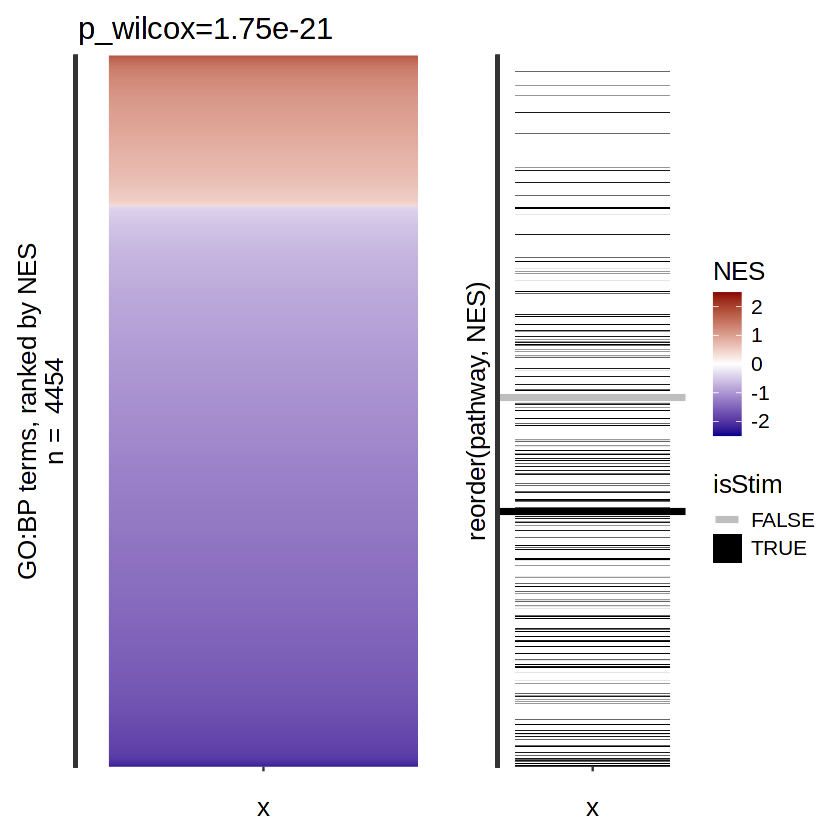

In [5]:
hm_plot(brm_6h_gsea)
ggsave("Panel_H.pdf", width=4)

In [5]:
brm_6h_gsea %>% filter(isStim==TRUE) %>% group_by(NES < 0) %>% summarize(n())

NES < 0,n()
<lgl>,<int>
FALSE,34
TRUE,400
NA,1


In [7]:
table(brm_6h_gsea$isStim, brm_6h_gsea$NES < 0) %>% fisher.test()


	Fisher's Exact Test for Count Data

data:  .
p-value = 4.491e-15
alternative hypothesis: true odds ratio is not equal to 1
95 percent confidence interval:
 2.404439 5.087156
sample estimates:
odds ratio 
  3.447362 
